<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_06_direction_and_layers_lawyers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 6 · Direction and layers: friends, advice and co-work

*M2 Network Analysis · Mapping collaboration with networks*

**The story so far.** Parts 2–5 used undirected collaboration ties. Now we move to directed, multi-layer social networks.

> **Today's question:** Co-inventing is mutual, but asking someone for advice is not. What changes when ties have a direction — and when people are tied in several ways at once?

**You will learn to**

1. Build **directed** networks and compute **in-degree**, **out-degree**, **PageRank** and **reciprocity**.
2. Compare reciprocity with what a random network would give.
3. Analyse a **multiplex** network with three layers (co-work, advice, friendship).
4. Measure **homophily** with attribute assortativity, and compare it across layers.

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

## 1. Why direction matters: a high-school warm-up

Students in an Illinois high school (1958) were asked to name their friends. *I name you* does not mean
*you name me*, so every tie is an arrow: a **directed** network (`nx.DiGraph`).

In [ ]:
import io, zipfile
from urllib.request import urlopen

zf = zipfile.ZipFile(io.BytesIO(urlopen(
    "https://networks.skewed.de/net/highschool/files/highschool.csv.zip").read()))
hs = pd.read_csv(zf.open("edges.csv"))
hs.columns = ["source", "target", "weight"]          # weight = named in 1 or 2 surveys
school = nx.from_pandas_edgelist(hs, "source", "target", "weight", create_using=nx.DiGraph)
print(school)

DiGraph with 70 nodes and 366 edges


- **in-degree** = how many name *you* (popularity)
- **out-degree** = how many *you* name (activity, sociability)
- **reciprocity** = the share of ties that are returned

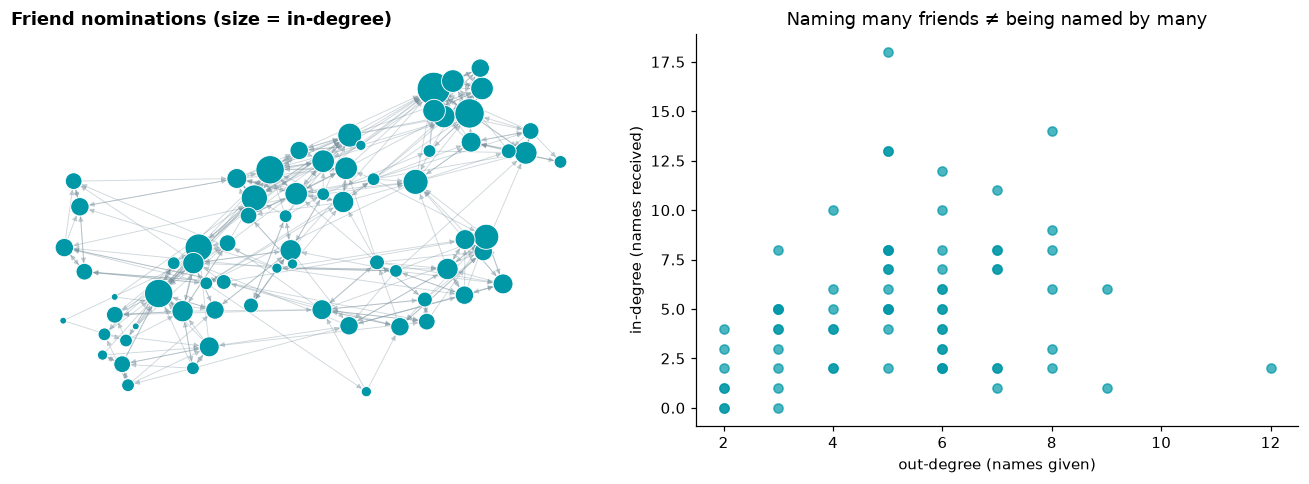

reciprocity: 0.503


In [ ]:
inout = pd.DataFrame({"in": dict(school.in_degree()), "out": dict(school.out_degree())})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ps = nx.spring_layout(school, seed=2)
draw(school, ps, ax=axes[0], node_size=[20 + 25 * inout.loc[n, "in"] for n in school], width=0.6,
     title="Friend nominations (size = in-degree)")
axes[1].scatter(inout["out"], inout["in"], color=TEAL, alpha=0.7)
axes[1].set(xlabel="out-degree (names given)", ylabel="in-degree (names received)",
            title="Naming many friends ≠ being named by many")
plt.tight_layout(); plt.show()

print("reciprocity:", round(nx.reciprocity(school), 3))

## 2. The case: a corporate law firm (Lazega)

Emmanuel Lazega studied **71 lawyers** in a US corporate law firm (1988–1991): 36 **partners** and 35 **associates**
in three offices. Each lawyer answered three questions about every colleague:

| layer | question (short) |
|---|---|
| **co-work** | *With whom have you worked on at least one case?* |
| **advice** | *To whom did you go for basic professional advice?* |
| **friendship** | *Whom do you socialise with outside work?* |

The same 71 people, tied in three different ways: a **multiplex** (multi-layer) network.

In [ ]:
BASE = "https://sds-aau.github.io/SDS-master/M2/data/LazegaLawyers/"

def load_layer(file):
    mat = pd.read_csv(BASE + file, sep=r"\s+", header=None)   # \s+ : the files use irregular spacing
    mat.index = mat.columns = range(1, len(mat) + 1)            # lawyer ids 1..71, like the attribute file
    return nx.from_pandas_adjacency(mat, create_using=nx.DiGraph)

layers = {"co-work": load_layer("ELwork.dat"),
          "advice": load_layer("ELadv.dat"),
          "friendship": load_layer("ELfriend.dat")}
for name, L in layers.items():
    print(f"{name:<11}", L)

co-work     DiGraph with 71 nodes and 756 edges
advice      DiGraph with 71 nodes and 892 edges
friendship  DiGraph with 71 nodes and 575 edges


**Attributes.** The first column of `ELattr.dat` is the lawyer id (also their seniority rank); the second is the
**status** (partner or associate).

In [ ]:
attr = pd.read_csv(BASE + "ELattr.dat", sep=r"\s+", header=None,
                   names=["id", "status", "gender", "office", "years", "age", "practice", "school"])
attr = attr.set_index("id").replace({
    "status":   {1: "partner", 2: "associate"},
    "gender":   {1: "man", 2: "woman"},
    "office":   {1: "Boston", 2: "Hartford", 3: "Providence"},
    "practice": {1: "litigation", 2: "corporate"},
    "school":   {1: "Harvard/Yale", 2: "UConn", 3: "other"},
})
for L in layers.values():
    nx.set_node_attributes(L, attr.to_dict("index"))
attr.head()

,status,gender,office,years,age,practice,school
id,,,,,,,
1,partner,man,Boston,31,64,litigation,Harvard/Yale
2,partner,man,Boston,32,62,corporate,Harvard/Yale
3,partner,man,Hartford,13,67,litigation,Harvard/Yale
4,partner,man,Boston,31,59,corporate,other
5,partner,man,Hartford,31,59,litigation,UConn


## 3. Three layers, one firm

We draw the three layers with the **same node positions** so that they can be compared directly.

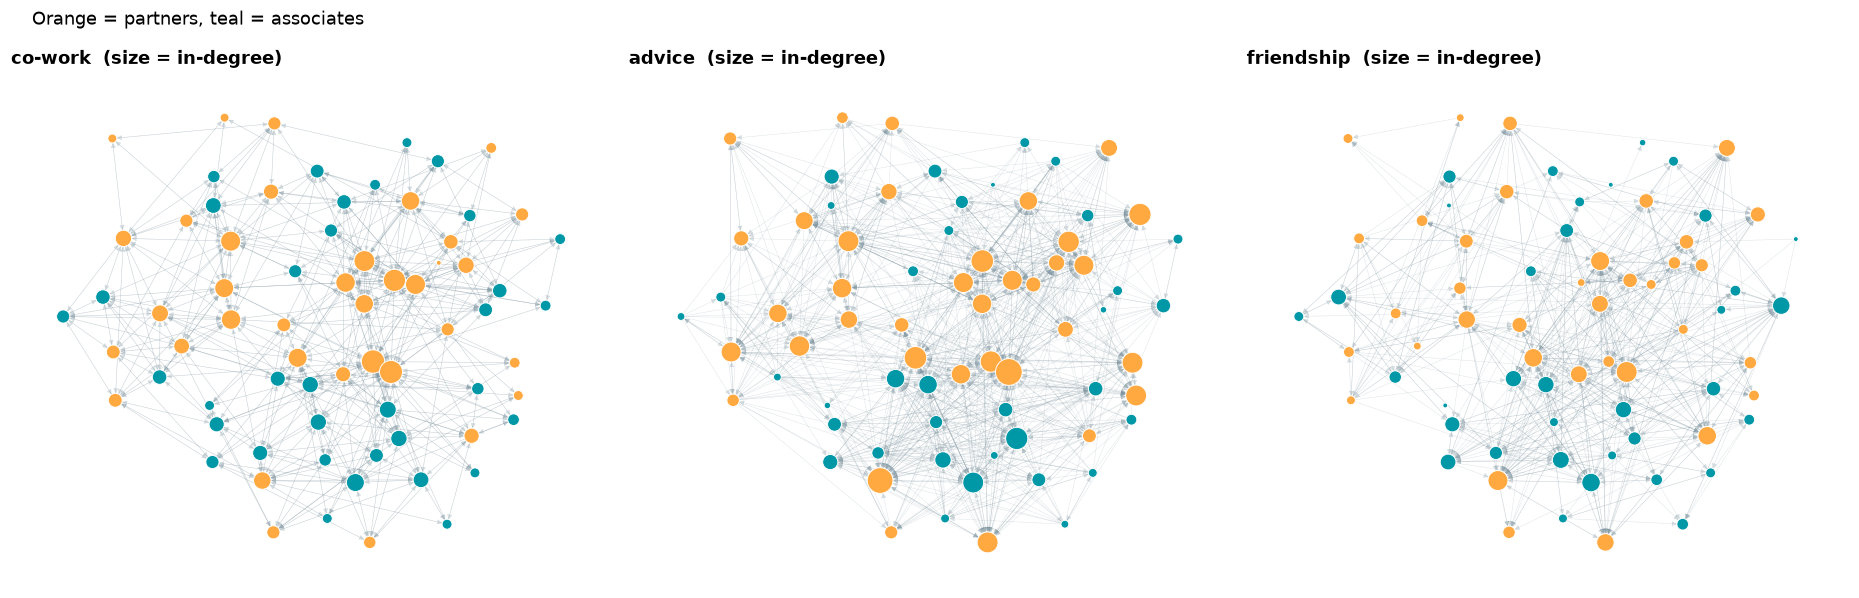

In [ ]:
pl = nx.kamada_kawai_layout(nx.Graph(layers["co-work"]))
status_color = [ORANGE if attr.loc[n, "status"] == "partner" else TEAL for n in pl]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (name, L) in zip(axes, layers.items()):
    indeg = dict(L.in_degree())
    draw(L, pl, ax=ax, node_size=[10 + 8 * indeg[n] for n in L], node_color=status_color,
         width=0.3, edge_alpha=0.25, title=f"{name}  (size = in-degree)")
fig.suptitle("Orange = partners, teal = associates", x=0.02, ha="left")
plt.tight_layout(); plt.show()

### Who is sought out? In-degree by status

In [ ]:
indeg = pd.DataFrame({name: dict(L.in_degree()) for name, L in layers.items()}).join(attr["status"])
indeg.groupby("status").mean().round(1)

,co-work,advice,friendship
status,,,
associate,8.6,7.3,6.8
partner,12.6,17.7,9.3


**Advice flows upward**: partners receive far more advice requests than associates. Co-work and friendship are
much more balanced. For directed networks, **PageRank** extends eigenvector centrality: you are important if
important people come to you.

In [ ]:
pr = pd.Series(nx.pagerank(layers["advice"]), name="pagerank")
pd.concat([pr, attr[["status", "office", "years"]]], axis=1).nlargest(5, "pagerank").round(3)

,pagerank,status,office,years
17,0.056,partner,Boston,23
1,0.046,partner,Boston,31
2,0.043,partner,Boston,32
26,0.040,partner,Boston,15
20,0.039,partner,Boston,19


## 4. Reciprocity: are ties returned?

Compare each layer with a **random directed network of the same density**: there a tie $j \to i$ exists with
probability equal to the density, whatever $i \to j$ does.

In [ ]:
rec = pd.DataFrame({
    name: {"reciprocity": nx.reciprocity(L), "density (random expectation)": nx.density(L)}
    for name, L in layers.items()}).T
rec["times more than random"] = rec["reciprocity"] / rec["density (random expectation)"]
rec.round(2)

,reciprocity,density (random expectation),times more than random
co-work,1.00,0.15,6.57
advice,0.39,0.18,2.19
friendship,0.61,0.12,5.29


### 🔎 Interpretation
- **Co-work** is (almost) perfectly reciprocal: working together is mutual by nature.
- **Friendship** is returned about 60% of the time — far above chance, but not always.
- **Advice** is the least reciprocal: you ask a senior colleague, they rarely ask you back. **Hierarchy** shows up as one-way ties.

## 5. Do the layers overlap?

Are your friends also your advisers and co-workers? We measure the overlap between two layers with the
**Jaccard index** of their tie sets (shared ties ÷ ties in either).

In [ ]:
def ties(L):
    return set(L.edges())

names = list(layers)
jac = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        A, B_ = ties(layers[a]), ties(layers[b])
        jac.loc[a, b] = len(A & B_) / len(A | B_)
jac.round(2)

,co-work,advice,friendship
co-work,1.00,0.34,0.20
advice,0.34,1.00,0.32
friendship,0.20,0.32,1.00


In [ ]:
adv, fr = ties(layers["advice"]), ties(layers["friendship"])
print(f"{len(adv & fr) / len(adv):.0%} of advice ties go to a friend, "
      f"while a random pair is friends {nx.density(layers['friendship']):.0%} of the time")

40% of advice ties go to a friend, while a random pair is friends 12% of the time


## 6. Homophily: do similar lawyers connect?

**Attribute assortativity** $r$ ranges from −1 to +1. $r > 0$: ties fall *within* groups more than chance would
predict (homophily, *birds of a feather*); $r < 0$: ties tend to *cross* groups; $r \approx 0$: no pattern.

In [ ]:
assort = pd.DataFrame({
    name: {a: nx.attribute_assortativity_coefficient(L, a)
           for a in ["office", "status", "practice", "gender", "school"]}
    for name, L in layers.items()}).round(2)
assort

,co-work,advice,friendship
office,0.57,0.48,0.60
status,-0.24,0.32,0.55
practice,0.57,0.46,0.18
gender,0.00,0.09,0.21
school,0.03,0.03,0.05


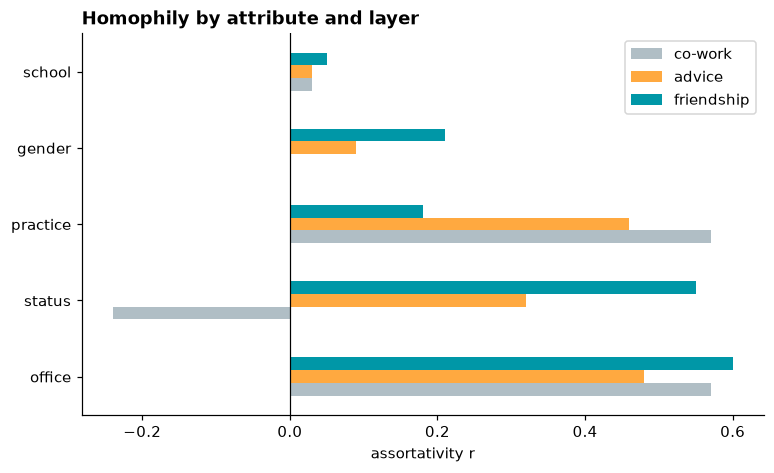

In [ ]:
assort.plot.barh(figsize=(8, 4.5), color=[GREY, ORANGE, TEAL])
plt.axvline(0, color="black", lw=0.8)
plt.title("Homophily by attribute and layer", loc="left", fontweight="bold")
plt.xlabel("assortativity r"); plt.show()

### 🔎 Interpretation
- **Office** is the strongest sorter in every layer: people work with, ask and befriend those nearby.
- **Status** matters a lot for **friendship** (partners socialise with partners), less for advice, and is
  **negative for co-work**: cases deliberately mix partners and associates, so co-work ties *cross* status.
- **Practice** (litigation vs corporate) organises co-work and advice — the work itself.

One caution: assortativity is a description, not a cause. Friends may choose the same office, or the same office may create friends.

## 7. Communities in a directed network

Most community algorithms expect undirected ties, so we first make the advice layer undirected and then use Louvain.
Do the communities follow the offices?

In [ ]:
adv_und = layers["advice"].to_undirected()
comms = sorted(nx.community.louvain_communities(adv_und, seed=42), key=len, reverse=True)
print("Q =", round(nx.community.modularity(adv_und, comms), 3))
pd.DataFrame([attr.loc[list(c), "office"].value_counts() for c in comms],
             index=[f"community {i}" for i in range(len(comms))]).fillna(0).astype(int)

Q = 0.282


office,Boston,Hartford,Providence
community 0,31,0,0
community 1,17,2,1
community 2,0,17,3


The advice communities largely **are the offices** (Hartford separates cleanly), and the big Boston office splits in
two. Check yourself whether that split follows `practice` (litigation vs corporate).

## 🧑‍💻 Your turn

1. Which lawyer has the highest **out-degree** in the advice layer? Is it a partner or an associate? What does that mean?
2. Friendship is returned 50% of the time in the high school and 61% in the law firm. What could explain the difference?
3. Build a **multiplex** summary: for each lawyer, in how many layers do they have an in-degree above the median?

<details><summary>Hint for 1</summary>

```python
out_adv = pd.Series(dict(layers["advice"].out_degree()))
attr.loc[out_adv.idxmax()]
```
</details>

In [ ]:
# your code here

## ✅ Key takeaways
- In **directed** networks, degree splits into **in-degree** (sought out) and **out-degree** (reaching out); PageRank is the directed eigenvector.
- **Reciprocity** reveals hierarchy: advice is asked upward and rarely returned.
- **Multiplex** networks tie the same people in several ways; layers overlap far more than chance.
- **Assortativity** measures homophily, and its pattern differs by layer.

## 🎓 The whole story
1. A network is nodes + edges + attributes (**Part 1**).
2. Patent records are two-mode; projection gives a collaboration network with a connected core (**Part 2**).
3. "Central" has many meanings: degree, closeness, betweenness, eigenvector (**Part 3**).
4. The core is a small world with clear communities (**Part 4**).
5. The same recipe at country level shows bridges and the effect of sampling (**Part 5**).
6. Direction and layers reveal hierarchy and homophily (**Part 6**).